# Dissertation Assignment 4
# HinSAGE Baseline Implementation
**Submitted by:<br>
Urvi Sharma <br>
Roll No: AM.EN.P2ARI2022 <br>
Date : 11-Nov-2021**

In [1]:
import pandas as pd
import numpy as np
from sklearn import preprocessing, feature_extraction, model_selection
from sklearn.metrics import mean_absolute_error, mean_squared_error

import stellargraph as sg
from stellargraph.mapper import HinSAGELinkGenerator
from stellargraph.layer import HinSAGE, link_regression
from tensorflow.keras import Model, optimizers, losses, metrics

import multiprocessing
import matplotlib.pyplot as plt
from stellargraph import StellarGraph
from tensorflow import keras
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

### Data Pre-Processing

In [2]:
df = pd.read_csv('normalized_ratings.csv')
df

,source,target,edge
0,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
1,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
2,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
3,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
4,ALJ66O1Y6SLHA,B000K2PJ4K,5.0
...,...,...,...
3171,A2077NII5H62R2,B005AGO4LU,5.0
3172,A2IBS6PIPAGAB5,B005AGO4LU,5.0
3173,A1GTC5EVSJNCQ8,B005AGO4LU,5.0
3174,A311XHHLM12MUT,B005AGO4LU,5.0


In [3]:
reviews = pd.read_csv("reviews.csv")
reviews

,rating,reviewTime,reviewerID,productID,style,reviewerName,reviewText,summary,unixReviewTime,Size,Color
0,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Orange'}",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Orange
1,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Black (3746...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Black (37467610) / Red/White
2,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Gray L...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Gray Logo
3,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue (37867...",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue (37867638-99) / Yellow
4,5,"09 4, 2015",ALJ66O1Y6SLHA,B000K2PJ4K,"{'Size:': ' Big Boys', 'Color:': ' Blue/Pink'}",Tonya B.,Great product and price!,Five Stars,1441324800,Big Boys,Blue/Pink
...,...,...,...,...,...,...,...,...,...,...,...
3171,5,"07 2, 2018",A2077NII5H62R2,B005AGO4LU,"{'Size:': ' 8.5 B(M) US', 'Color:': ' Green Gl...",Amazon Customer,Perfect fit!,Five Stars,1530489600,8.5 B(M) US,Green Glow/Seaweed - Hasta - White
3172,5,"06 28, 2018",A2IBS6PIPAGAB5,B005AGO4LU,"{'Size:': ' 5 B(M) US', 'Color:': ' Wolf Grey/...",J. Avila,My favorite cross trainers!,Comfortable,1530144000,5 B(M) US,Wolf Grey/Black-pink Blast/White
3173,5,"06 25, 2018",A1GTC5EVSJNCQ8,B005AGO4LU,"{'Size:': ' 8 B(M) US', 'Color:': ' Blue Tint/...",Amazon Customer,Love them fit perfect,Five Stars,1529884800,8 B(M) US,Blue Tint/Green Glow/Hasta/White
3174,5,"06 20, 2018",A311XHHLM12MUT,B005AGO4LU,"{'Size:': ' 9 B(M) US', 'Color:': ' Blue Tint/...",Peter,Favorite Nike shoe ever! The flex sole is exce...,Love them!,1529452800,9 B(M) US,Blue Tint/Green Glow/Hasta/White


In [4]:
nr = reviews.drop(columns = ['rating','productID','reviewerName','summary','reviewText','unixReviewTime','style'])

In [5]:
nr = nr.drop_duplicates(subset=['reviewerID']).set_index('reviewerID')
nr.index.name = 'source'
nr = pd.get_dummies(nr, columns = ['reviewTime','Size','Color'])
nr

,"reviewTime_01 1, 2017","reviewTime_01 10, 2017","reviewTime_01 10, 2018","reviewTime_01 11, 2018","reviewTime_01 12, 2017","reviewTime_01 13, 2017","reviewTime_01 15, 2017","reviewTime_01 18, 2017","reviewTime_01 18, 2018","reviewTime_01 20, 2017",...,Color_Pink Blast/Stealth/Hyper Pink/White,Color_Plure Platinum/Blue Glow/Wolf Grey,Color_Pure Platinum/Blue Glow/Wolf Grey,Color_Racer Blue/Obsidian/Blue Tint,Color_Red/White/Blue,Color_White/Black,Color_White/Hyper Pink/Pure Platinum/Wolf Grey,Color_White/Metallic Silver/Black,Color_Wolf Grey/Black-pink Blast/White,Color_Wolf Grey/Platinum/White/Crimson
source,,,,,,,,,,,,,,,,,,,,,
ALJ66O1Y6SLHA,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A3W11493KS6Z2L,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
A3HX4X3TIABWOV,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AW8UBYMNJ894V,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A265UZVOZWTTXQ,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A2077NII5H62R2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A2IBS6PIPAGAB5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
A1GTC5EVSJNCQ8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
pr = reviews.drop(columns = ['rating','reviewerID','reviewerName','summary','reviewText','unixReviewTime','style'])

In [7]:
pr = pr.drop_duplicates(subset=['productID']).set_index('productID')
pr.index.name = 'target'
pr = pd.get_dummies(pr, columns = ['reviewTime','Size','Color'])
pr

,"reviewTime_01 25, 2018","reviewTime_01 29, 2016","reviewTime_02 1, 2018","reviewTime_02 10, 2018","reviewTime_02 19, 2018","reviewTime_02 8, 2018","reviewTime_03 12, 2018","reviewTime_03 20, 2016","reviewTime_03 23, 2016","reviewTime_03 24, 2016",...,Color_Blue/Orange,Color_Bluestone Wash,Color_Bright Mango/Crimson/White/Blue,Color_Charcoal Heather,Color_Cool Grey/Team Orange/White/Platinum,Color_Dark Red-EGC1B01C,Color_Fireman (Red),Color_Immergruen Black,Color_Multi,Color_Red
target,,,,,,,,,,,,,,,,,,,,,
B000K2PJ4K,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
B000KPIHQ4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B000V0IBDM,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B000YFSR5G,0,0,0,0,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
B000YFSR4W,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B0012DR1LU,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B0014F8TIU,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
B0014HA6VG,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
B0017LD0BM,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


We have created 'nr' and 'pr' are dataframes containing node-feature vectors for user nodes and item nodes resepectively

### Graph Creation

In [8]:
G = StellarGraph({'source' : nr, 'target' : pr},edges=df, edge_type_default="edge")

In [9]:
print(G.info())

StellarGraph: Undirected multigraph
 Nodes: 437, Edges: 3176

 Node types:
  source: [406]
    Features: float32 vector, length 404
    Edge types: source-edge->target
  target: [31]
    Features: float32 vector, length 59
    Edge types: target-edge->source

 Edge types:
    source-edge->target: [3176]
        Weights: all 1 (default)
        Features: float32 vector, length 1


Specify the minibatch size

In [10]:
batch_size = 200
epochs = 20
# Use 70% of edges for training, the rest for testing:
train_size = 0.7
test_size = 0.3
num_samples = [8, 4]

### Data Splitting

Split the edges into train and test sets for model training/evaluation:

In [11]:
edges_train, edges_test = model_selection.train_test_split(
    df, train_size=train_size, test_size=test_size
)

edgelist_train = list(edges_train[["source", "target"]].itertuples(index=False))
edgelist_test = list(edges_test[["source", "target"]].itertuples(index=False))

labels_train = edges_train["edge"]
labels_test = edges_test["edge"]

### HinSAGE Model Generation

In [12]:
generator = HinSAGELinkGenerator(
    G, batch_size, num_samples, head_node_types=["source", "target"]
)
train_gen = generator.flow(edgelist_train, labels_train, shuffle=True)
test_gen = generator.flow(edgelist_test, labels_test)

In [13]:
generator.schema.type_adjacency_list(generator.head_node_types, len(num_samples))

[('source', [2]),
 ('target', [3]),
 ('target', [4]),
 ('source', [5]),
 ('source', []),
 ('target', [])]

In [14]:
generator.schema.schema

{'source': [EdgeType(n1='source', rel='edge', n2='target')],
 'target': [EdgeType(n1='target', rel='edge', n2='source')]}

In [15]:
hinsage_layer_sizes = [32, 32]
assert len(hinsage_layer_sizes) == len(num_samples)

hinsage = HinSAGE(
    layer_sizes=hinsage_layer_sizes, generator=generator, bias=True, dropout=0.0
)

In [16]:
# Expose input and output sockets of hinsage:
x_inp, x_out = hinsage.in_out_tensors()

In [17]:
# Final estimator layer
score_prediction = link_regression(edge_embedding_method="concat")(x_out)

link_regression: using 'concat' method to combine node embeddings into edge embeddings


**Create the Keras model, and compile it by specifying the optimizer, loss function to optimise, and metrics for diagnostics:**

In [18]:
import tensorflow.keras.backend as K


def root_mean_square_error(s_true, s_pred):
    return K.sqrt(K.mean(K.pow(s_true - s_pred, 2)))


model = Model(inputs=x_inp, outputs=score_prediction)
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-2),
    loss=losses.mean_squared_error,
    metrics=[root_mean_square_error, metrics.mae],
)

In [19]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_3 (InputLayer)            [(None, 8, 59)]      0                                            
__________________________________________________________________________________________________
input_5 (InputLayer)            [(None, 32, 404)]    0                                            
__________________________________________________________________________________________________
input_6 (InputLayer)            [(None, 32, 59)]     0                                            
__________________________________________________________________________________________________
input_1 (InputLayer)            [(None, 1, 404)]     0                                            
______________________________________________________________________________________________

In [20]:
# Specify the number of workers to use for model training
num_workers = 4

Untrained model's Test Evaluation:

In [21]:
test_metrics = model.evaluate(
    test_gen, verbose=1, use_multiprocessing=False, workers=num_workers
)

print("Untrained model's Test Evaluation:")
for name, val in zip(model.metrics_names, test_metrics):
    print("\t{}: {:0.4f}".format(name, val))

5/5 [==============================] - 3s 26ms/step - loss: 21.3714 - root_mean_square_error: 4.6245 - mean_absolute_error: 4.4977
Untrained model's Test Evaluation:
	loss: 21.3714
	root_mean_square_error: 4.6245
	mean_absolute_error: 4.4977


Train the model by feeding the data from the graph in minibatches, using mapper_train, and get validation metrics after each epoch:

In [22]:
history = model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=epochs,
    verbose=1,
    shuffle=False,
    use_multiprocessing=False,
    workers=num_workers,
)

Epoch 1/20
12/12 [==============================] - 9s 357ms/step - loss: 9.3506 - root_mean_square_error: 2.9080 - mean_absolute_error: 2.8306 - val_loss: 3.8968 - val_root_mean_square_error: 1.9740 - val_mean_absolute_error: 1.8481
Epoch 2/20
12/12 [==============================] - 5s 329ms/step - loss: 2.7519 - root_mean_square_error: 1.6203 - mean_absolute_error: 1.5391 - val_loss: 1.4997 - val_root_mean_square_error: 1.2213 - val_mean_absolute_error: 1.1102
Epoch 3/20
12/12 [==============================] - 4s 262ms/step - loss: 1.2228 - root_mean_square_error: 1.1080 - mean_absolute_error: 0.9483 - val_loss: 1.1092 - val_root_mean_square_error: 1.0455 - val_mean_absolute_error: 0.8132
Epoch 4/20
12/12 [==============================] - 4s 291ms/step - loss: 1.0913 - root_mean_square_error: 1.0291 - mean_absolute_error: 0.7598 - val_loss: 1.1484 - val_root_mean_square_error: 1.0633 - val_mean_absolute_error: 0.7509
Epoch 5/20
12/12 [==============================] - 4s 265ms/ste

Plot training history.

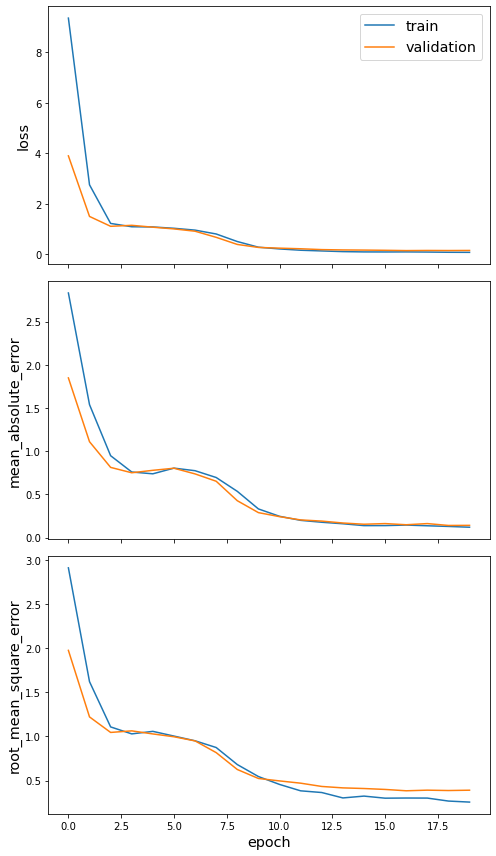

In [23]:
sg.utils.plot_history(history)

### Model Evaluation

In [24]:
test_metrics = model.evaluate(
    test_gen, use_multiprocessing=False, workers=num_workers, verbose=1
)

print("Test Evaluation:")
for name, val in zip(model.metrics_names, test_metrics):
    print("\t{}: {:0.4f}".format(name, val))

5/5 [==============================] - 1s 27ms/step - loss: 0.1507 - root_mean_square_error: 0.3886 - mean_absolute_error: 0.1414
Test Evaluation:
	loss: 0.1507
	root_mean_square_error: 0.3886
	mean_absolute_error: 0.1414


In [25]:
y_true = labels_test
# Predict the rankings using the model:
y_pred = model.predict(test_gen)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
print("\nModel Test set metrics:")
print("\troot_mean_square_error = ", rmse)
print("\tmean_absolute_error = ", mae)


Model Test set metrics:
	root_mean_square_error =  0.39302007927608734
	mean_absolute_error =  0.14357276211338635


Compare the distributions of predicted and true rankings for the test set:

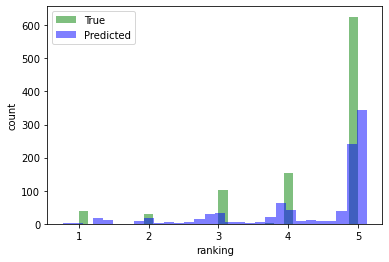

In [26]:
h_true = plt.hist(y_true, bins=30, facecolor="green", alpha=0.5)
h_pred = plt.hist(y_pred, bins=30, facecolor="blue", alpha=0.5)
plt.xlabel("ranking")
plt.ylabel("count")
plt.legend(("True", "Predicted"))
plt.show()